In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import rel_entr
from scipy.spatial.distance import jensenshannon

In [2]:
df_test = pd.read_csv("../../data/predictions_test.csv")
df_train = pd.read_csv("../../data/predictions_train.csv")

In [3]:
df_train.head()

,row,split,src,trg,pred,verdict,correct,logprob,min_tok_prob,finished,...,pred_n_terms,pred_max_depth,pred_max_const,pred_n_and,pred_n_or,pred_n_xor,pred_n_not,pred_n_add,pred_n_sub,pred_n_mul
0,50997,train,-2*(~x&~z)+2*(x^~z)+2*(~x&y^~z)-(y^~z)-(-1),-(~x&(y^z))+(x&(y^z)),-(~x&(y^z))-(x&(y^z)),wrong,False,-1.141468,0.413235,True,...,2,2,0,2,0,2,1,0,2,0
1,28883,train,3*(x^y)-4*(x&~y)+2*(x|~y)-(~x)+1,y,y,exact,True,-0.054658,0.946844,True,...,1,0,0,0,0,0,0,0,0,0
2,7657,train,(~(x^y))-(~y)+(x|~y)-(x|y)+1,-2*(x^y),-2*(x^y),exact,True,-0.015617,0.985480,True,...,1,1,2,0,0,1,0,0,1,1
3,490,train,-(~(x^y))+2*(~x)+3*x-y+1,2*(x&~y),2*(x&~y),exact,True,-0.001282,0.998992,True,...,1,1,2,1,0,0,1,0,0,1
4,5940,train,2*(~y)-(~x|y)-(~(x&y))+2*y-(x|y),-(~x&y),-(~x&y),exact,True,-0.165135,0.905910,True,...,1,1,0,1,0,0,1,0,1,0


## 1. Train/test relative sample frequencies histograms

In [4]:
def plot_relative_sample_frequencies(label_name, df_train, df_test):
    df_train_terms_count = df_train.groupby(label_name)["correct"].count()
    df_test_terms_count = df_test.groupby(label_name)["correct"].count()

    joint_df = pd.concat([df_train_terms_count, df_test_terms_count], axis=1).fillna(0)

    indices, train_counts, test_counts = joint_df.index, joint_df.iloc[:, 0].to_numpy(), joint_df.iloc[:, 1].to_numpy().astype(np.int64)

    n_samples_train = df_train.shape[0]
    n_samples_test = df_test.shape[0]
    
    train_rel_counts = (train_counts / n_samples_train) * 100
    test_rel_counts = (test_counts / n_samples_test) * 100

    # # to plot absolute counts:
    # train_rel_counts = train_counts
    # test_rel_counts = test_counts

    rel_counts = {
        'train': train_rel_counts,
        'test': test_rel_counts,
    }

    fig, ax = plt.subplots(layout='constrained', figsize=(16, 5))

    res = ax.grouped_bar(rel_counts, tick_labels=indices, group_spacing=1)

    # uncomment this to also show percentages above each bar (may be cluttered)
    for container in res.bar_containers:
        ax.bar_label(container, fmt="%.1f", padding=3)

    ax.set_ylabel('rel sample freq')
    ax.set_xlabel(label_name)
    ax.set_title(f'relative sample count vs {label_name}')
    ax.legend(loc='upper left', ncols=3)

    plt.show()

In [5]:
labels_ = ['src_len', 'src_n_vars', 'src_n_terms',
       'src_max_depth', 'src_max_const', 'src_n_and', 'src_n_or', 'src_n_xor',
       'src_n_not', 'src_n_add', 'src_n_sub', 'src_n_mul', 'trg_len',
       'trg_n_vars', 'trg_n_terms', 'trg_max_depth', 'trg_max_const',
       'trg_n_and', 'trg_n_or', 'trg_n_xor', 'trg_n_not', 'trg_n_add',
       'trg_n_sub', 'trg_n_mul', 'pred_len', 'pred_n_vars', 'pred_n_terms',
       'pred_max_depth', 'pred_max_const', 'pred_n_and', 'pred_n_or',
       'pred_n_xor', 'pred_n_not', 'pred_n_add', 'pred_n_sub', 'pred_n_mul']

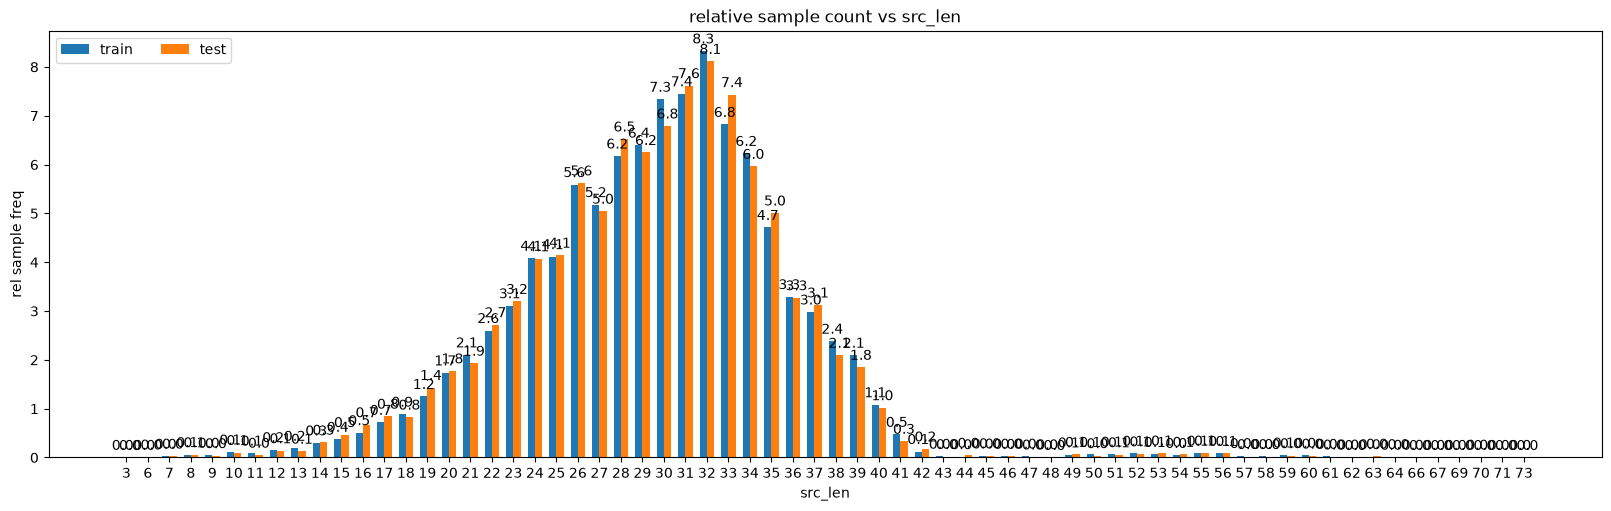

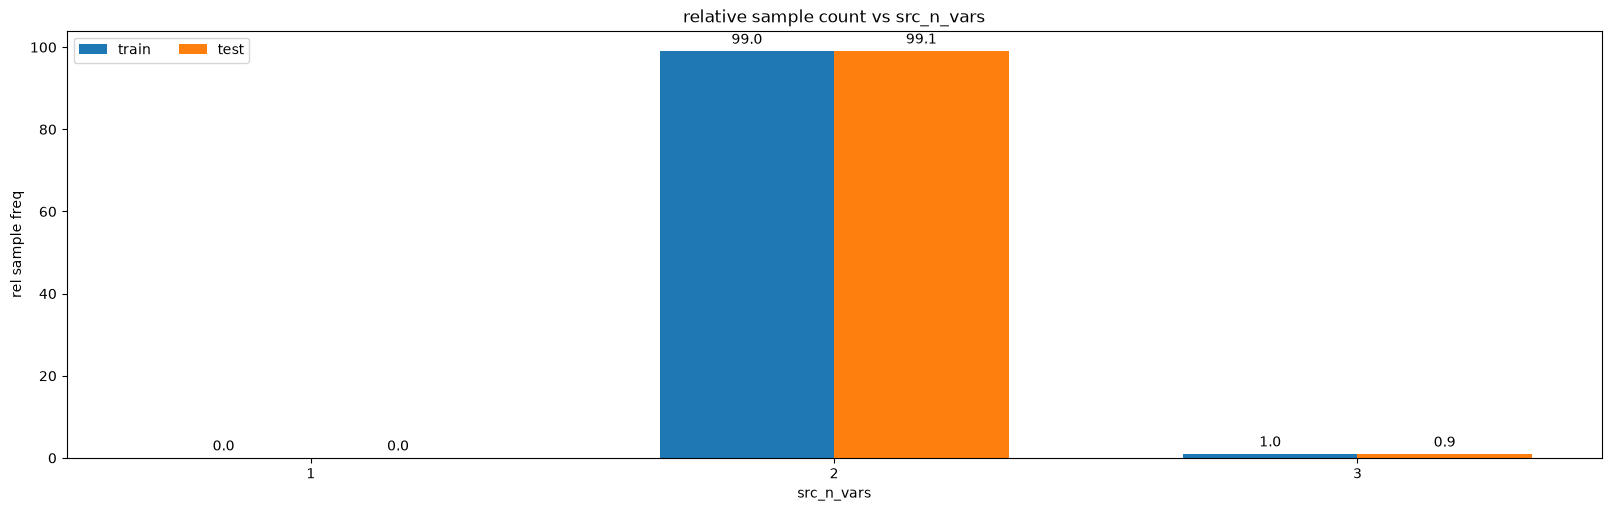

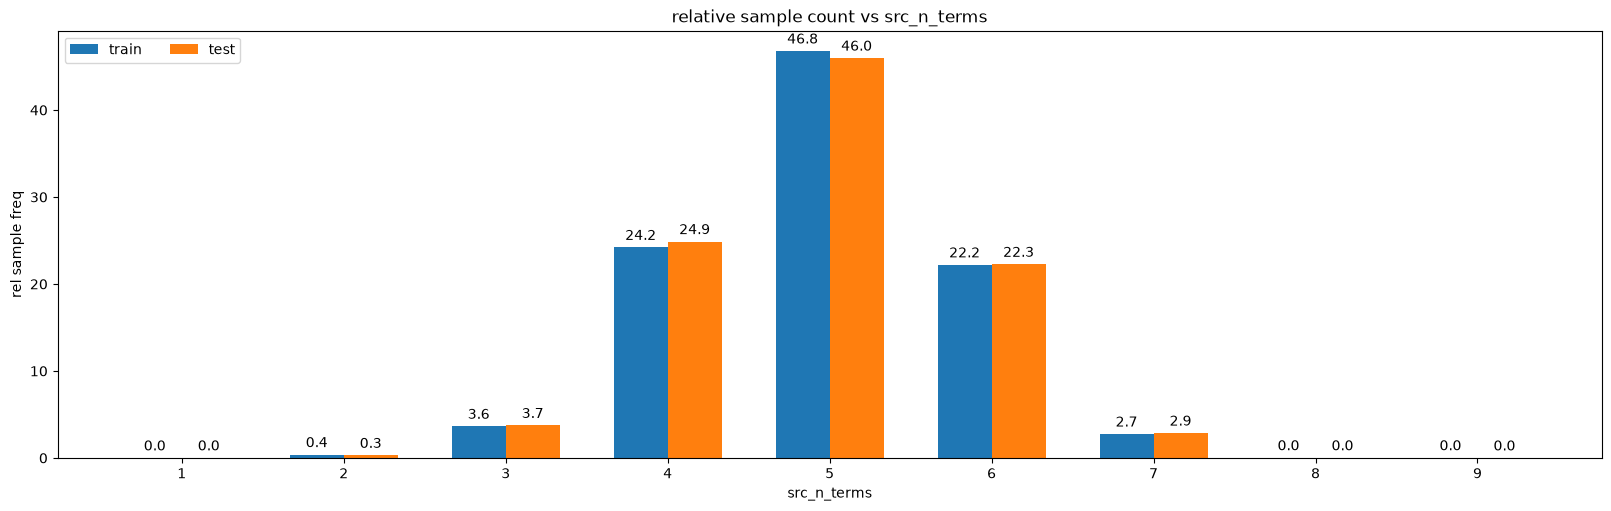

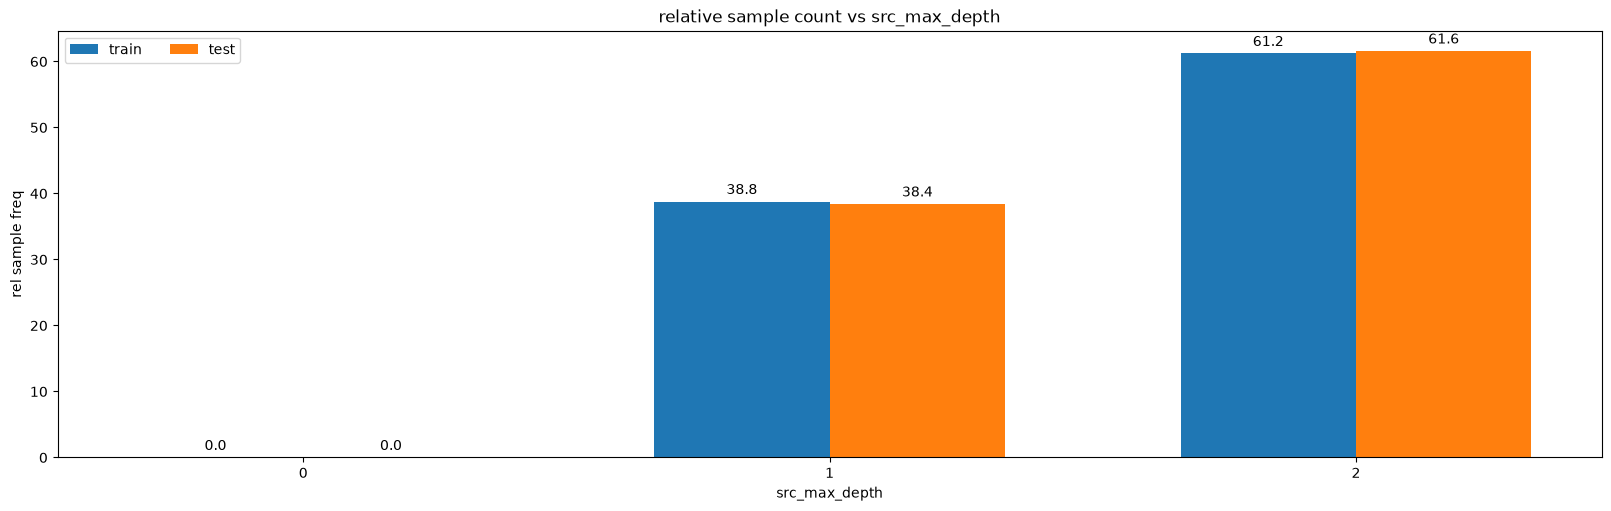

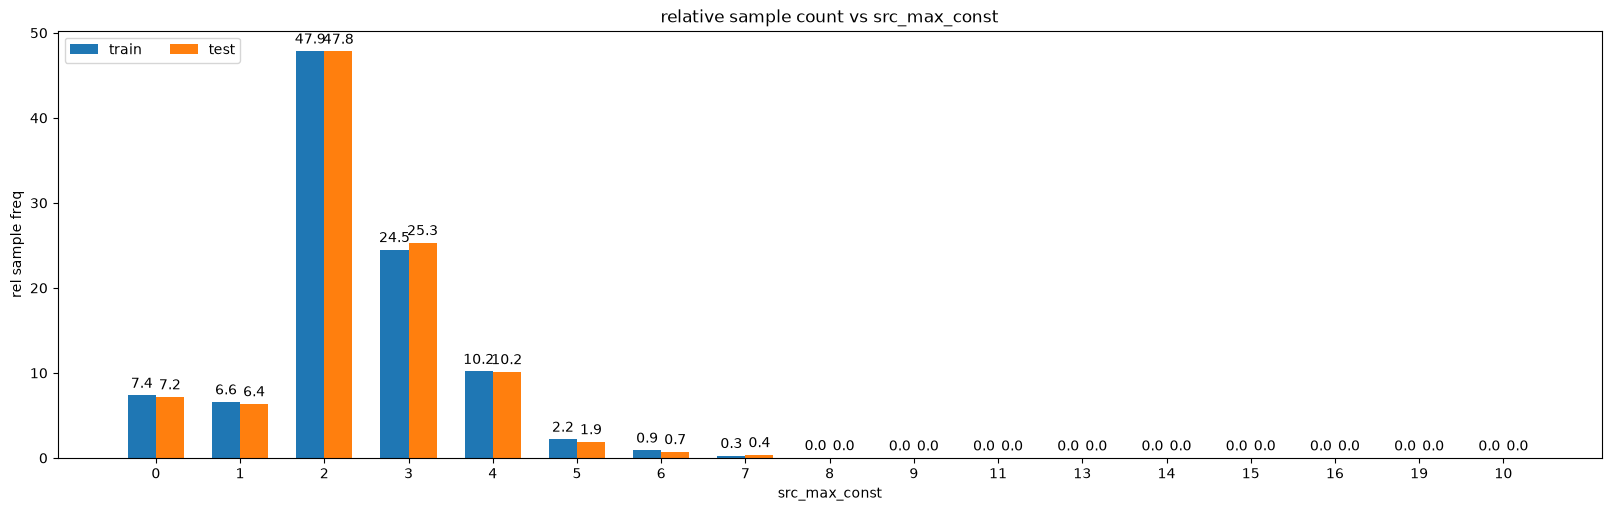

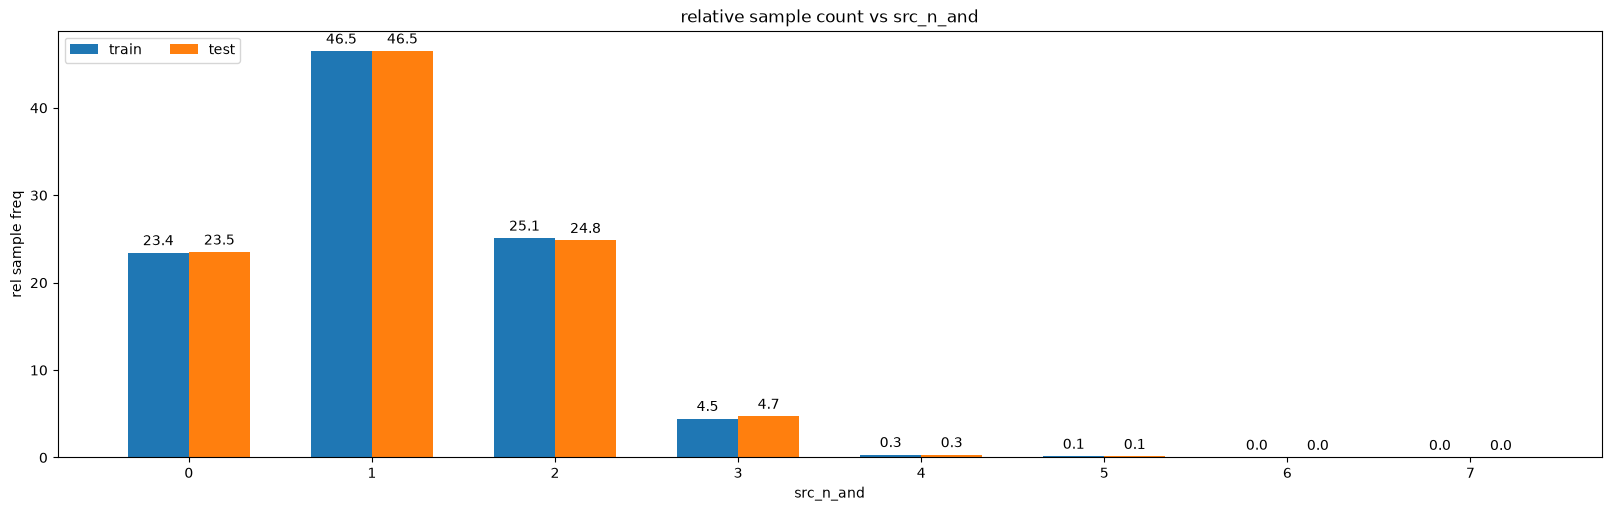

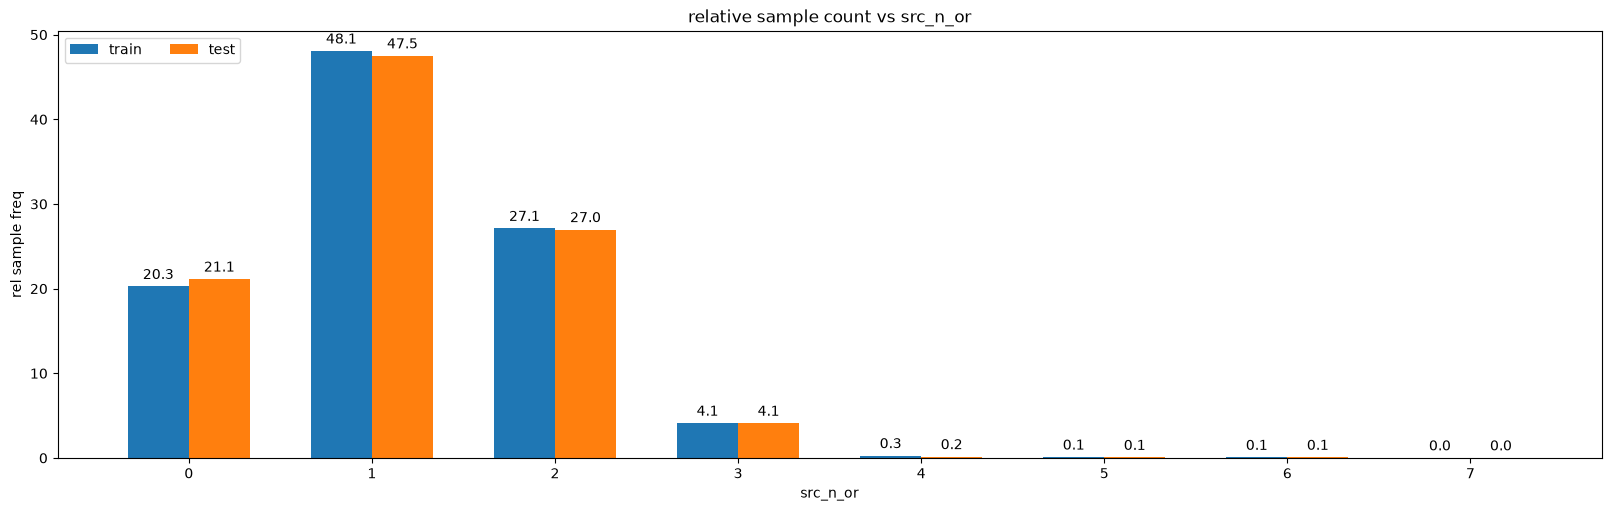

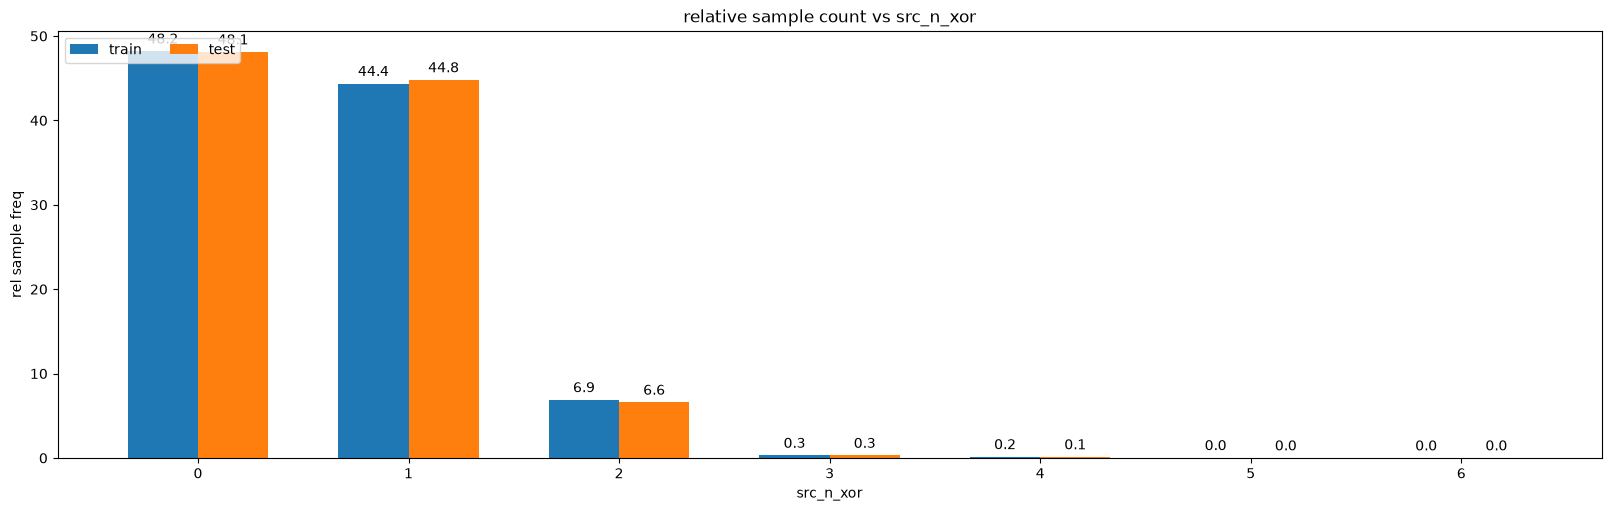

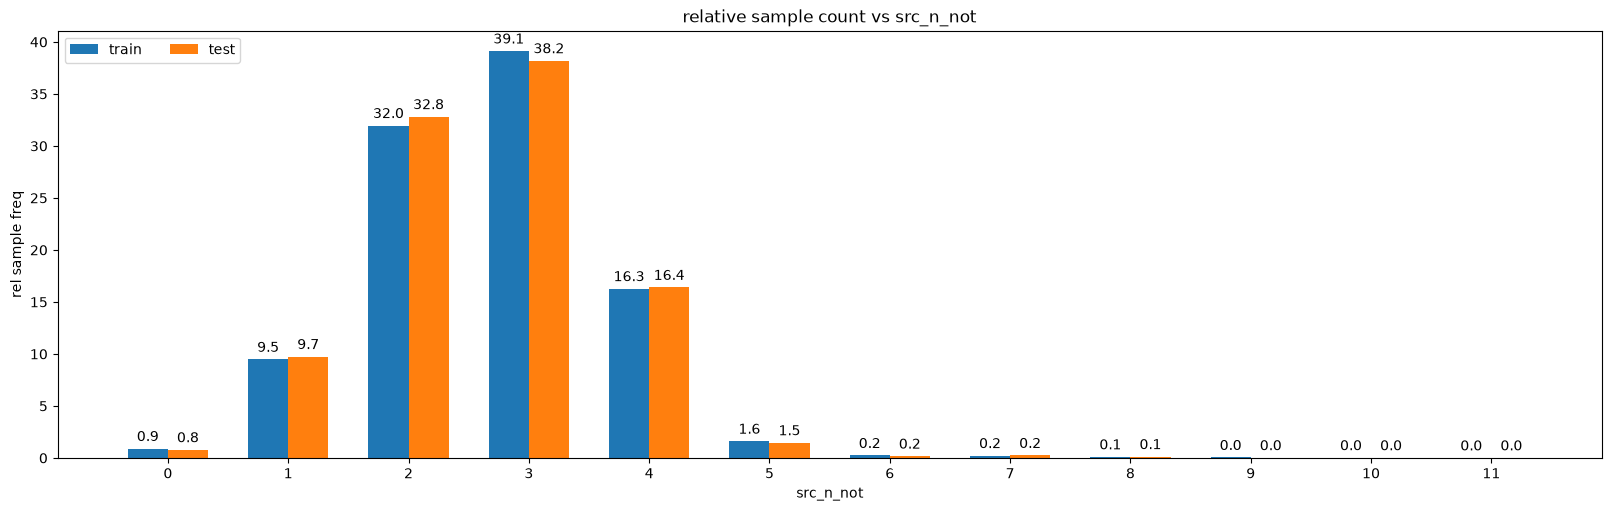

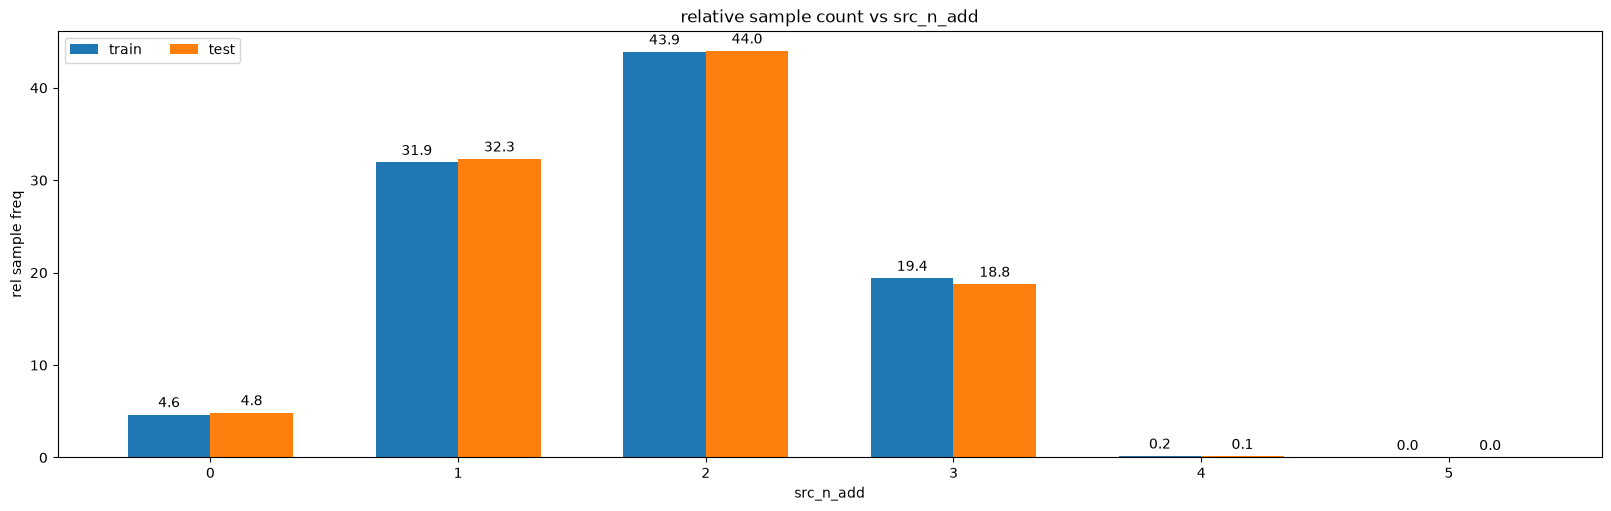

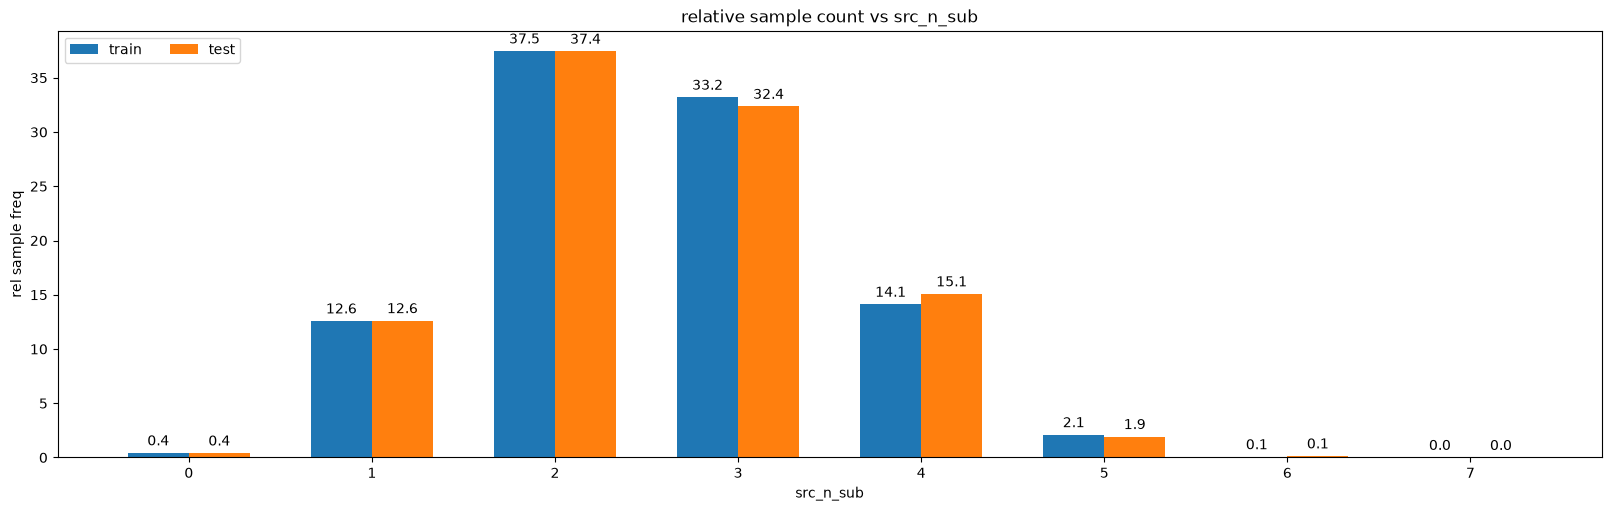

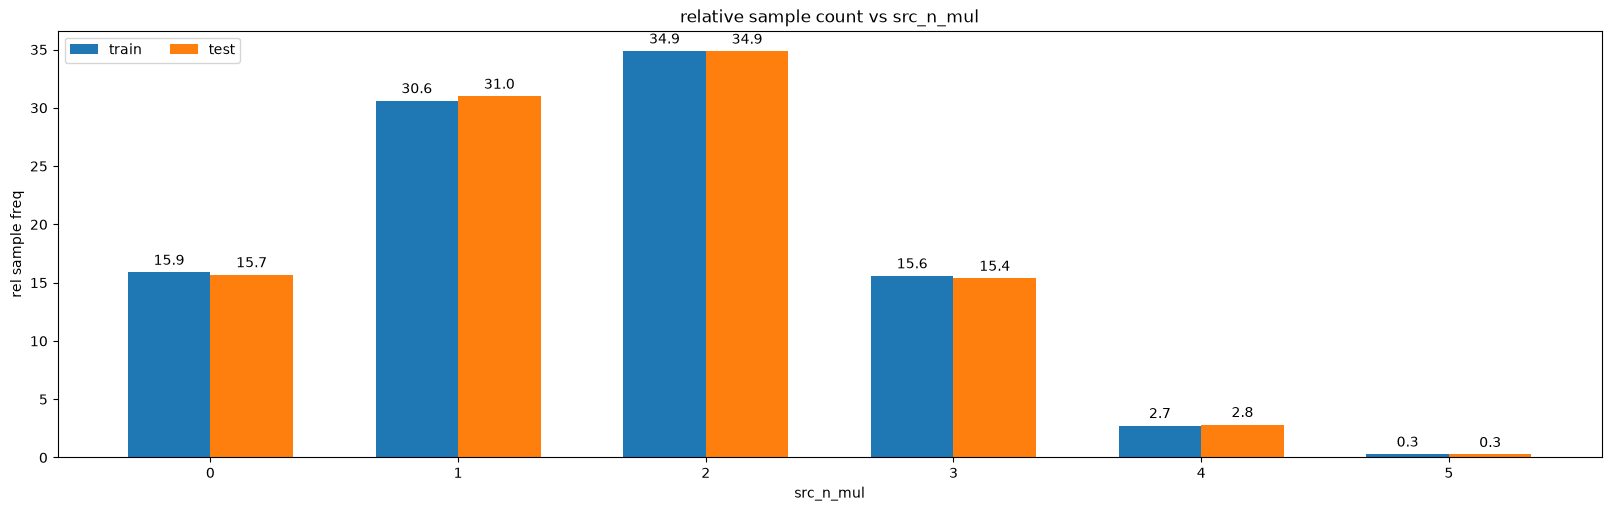

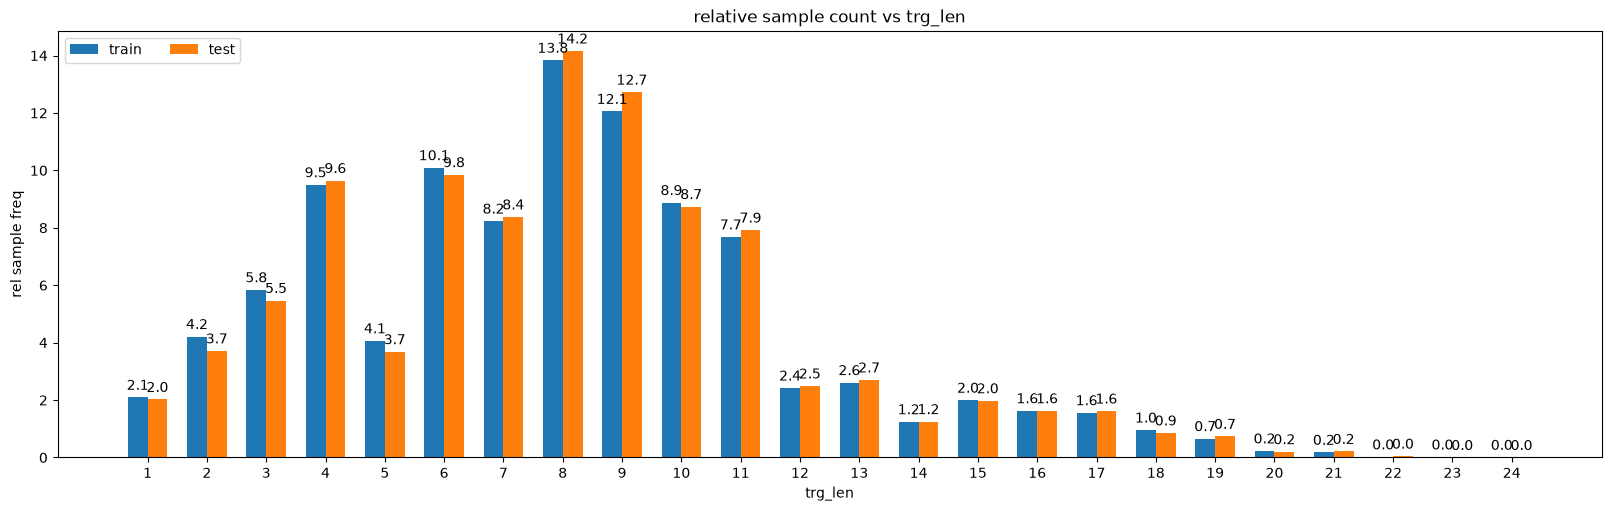

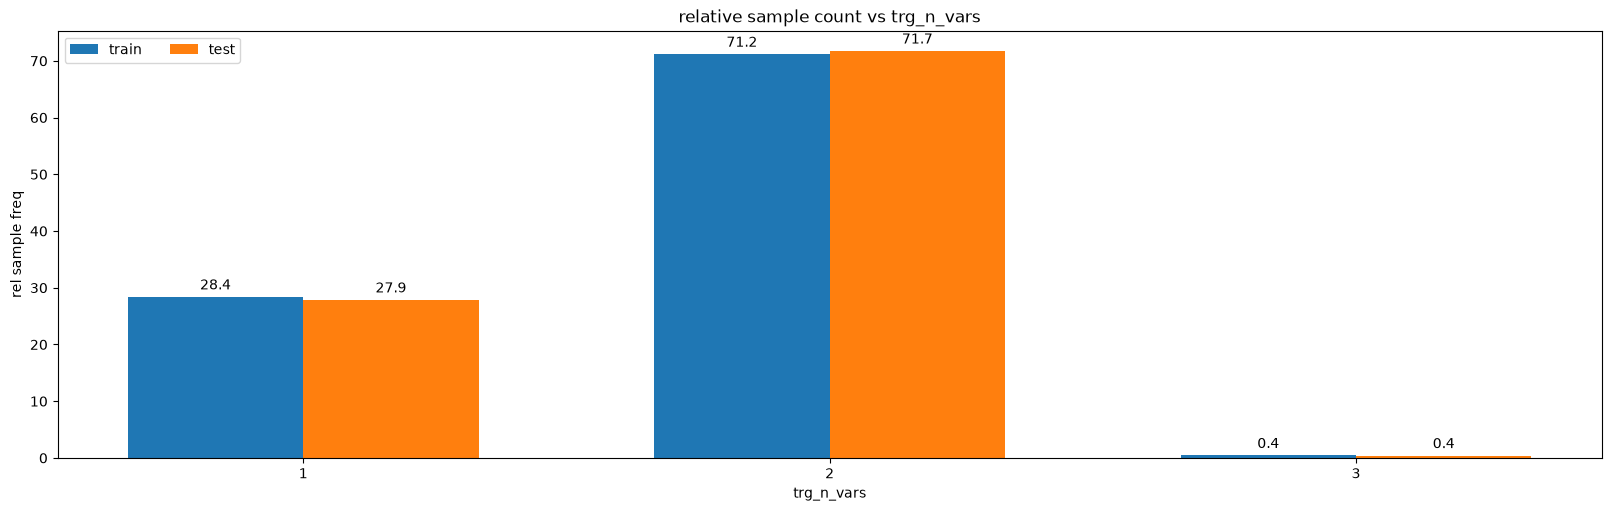

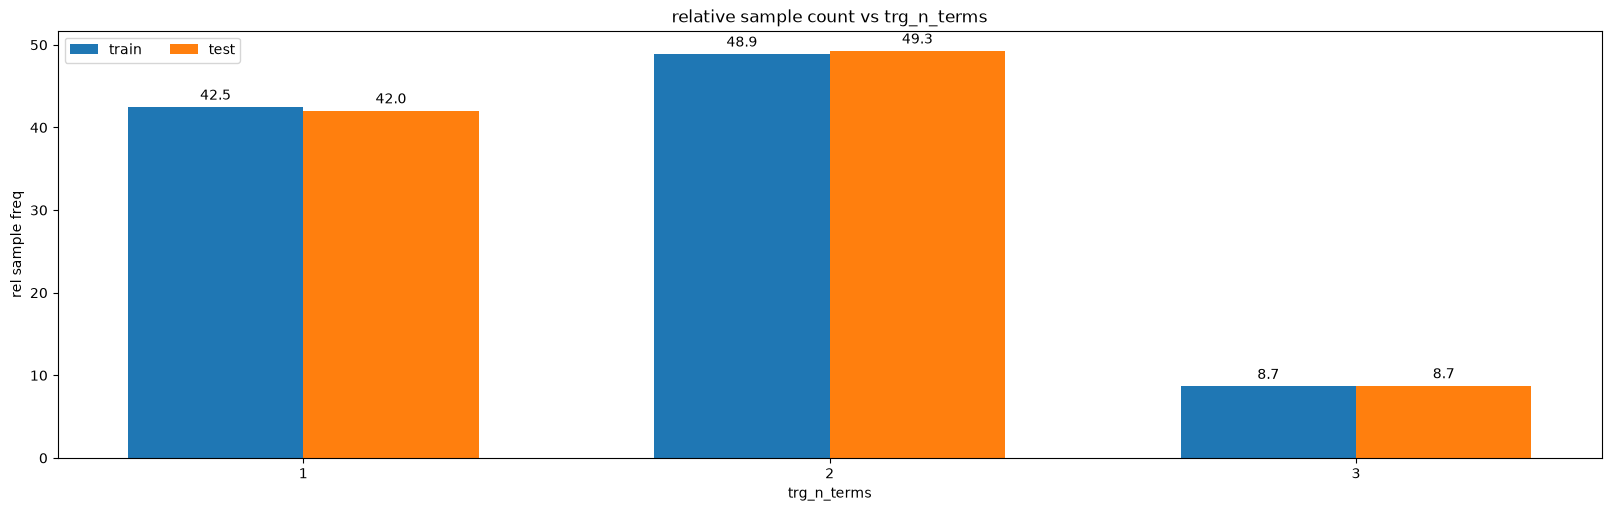

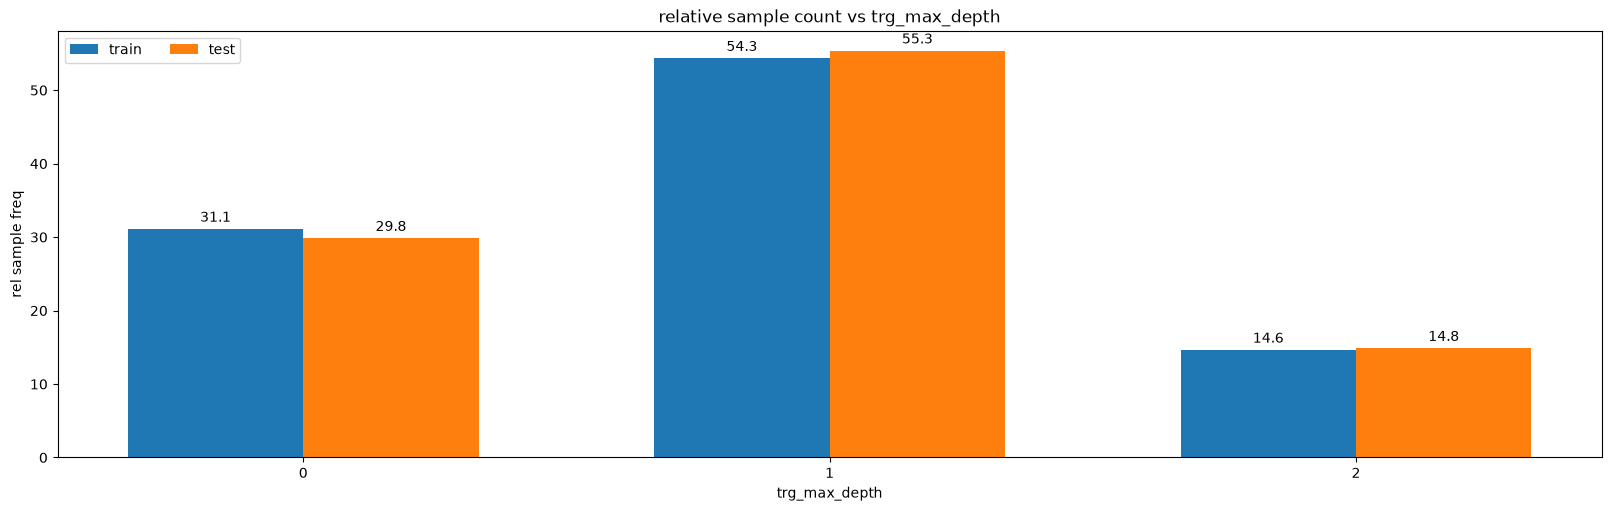

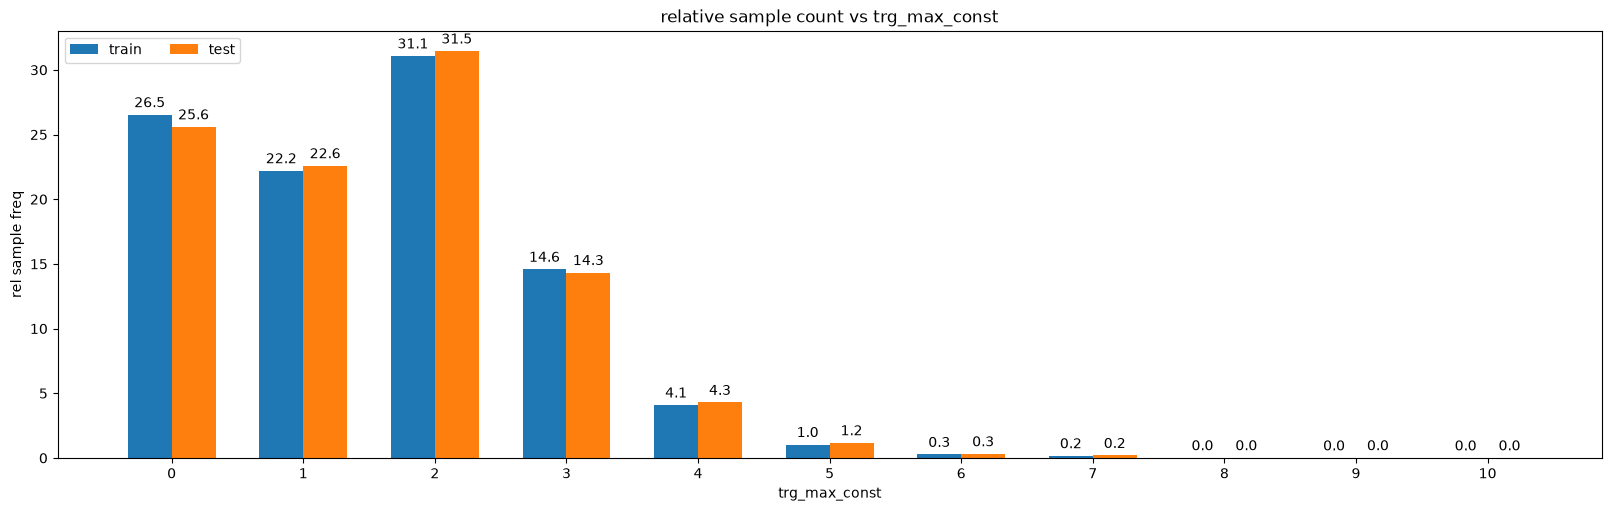

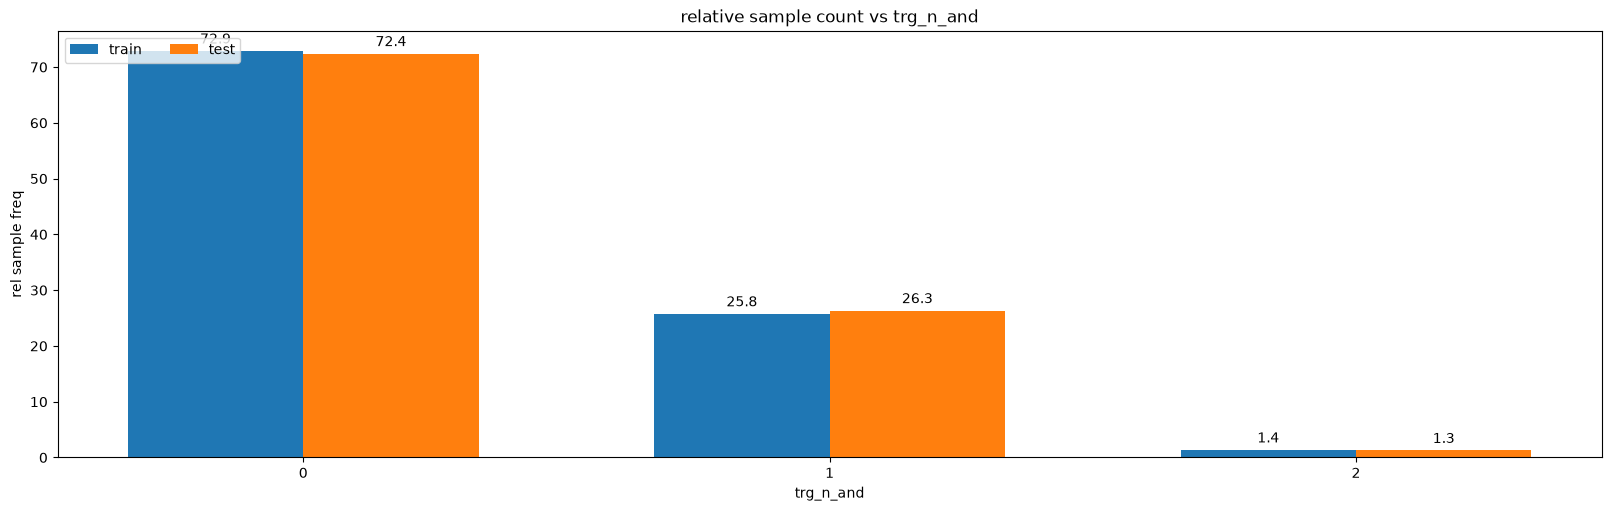

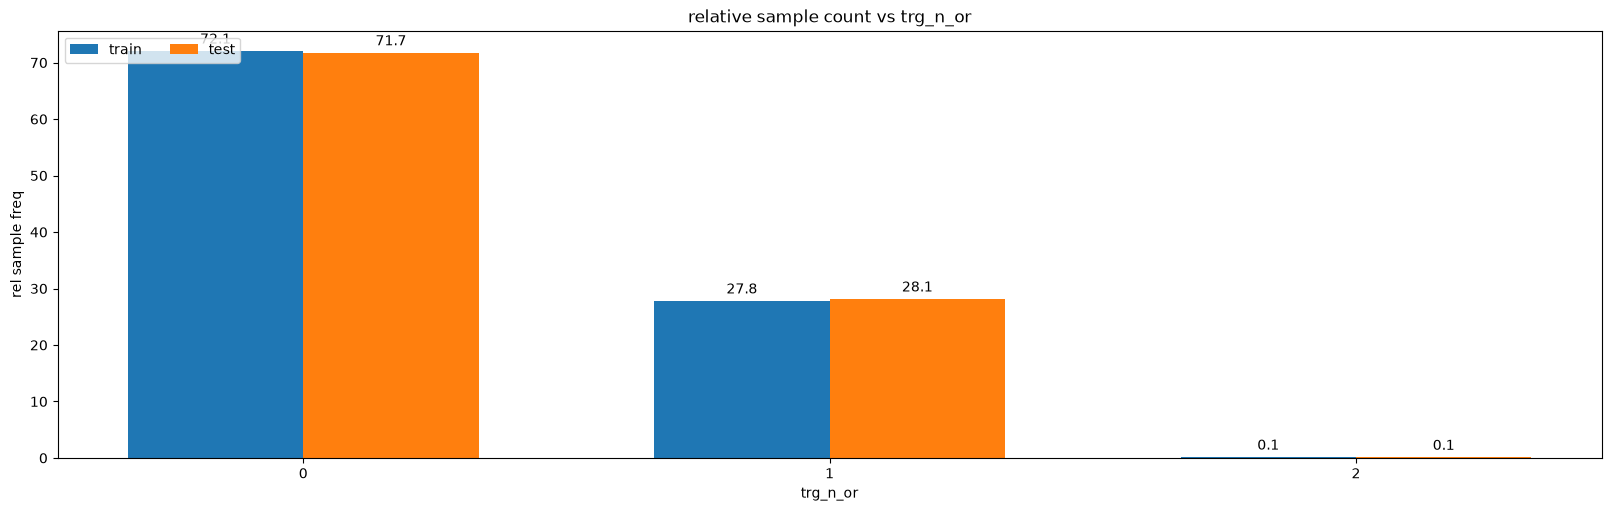

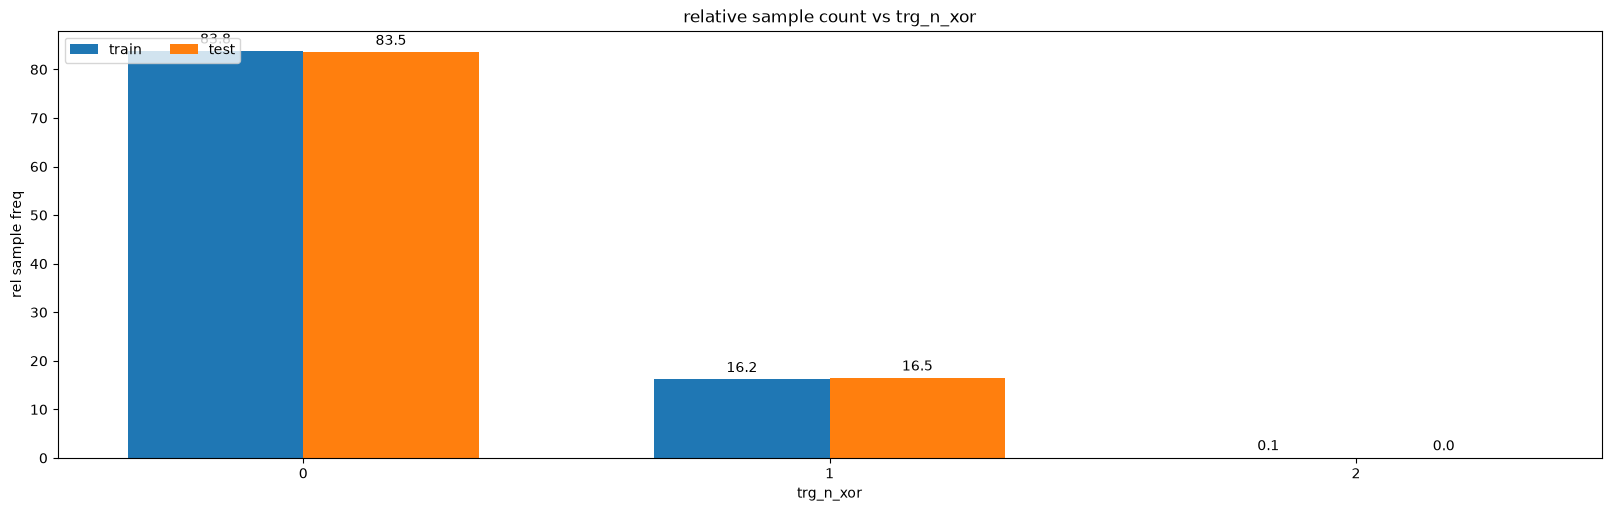

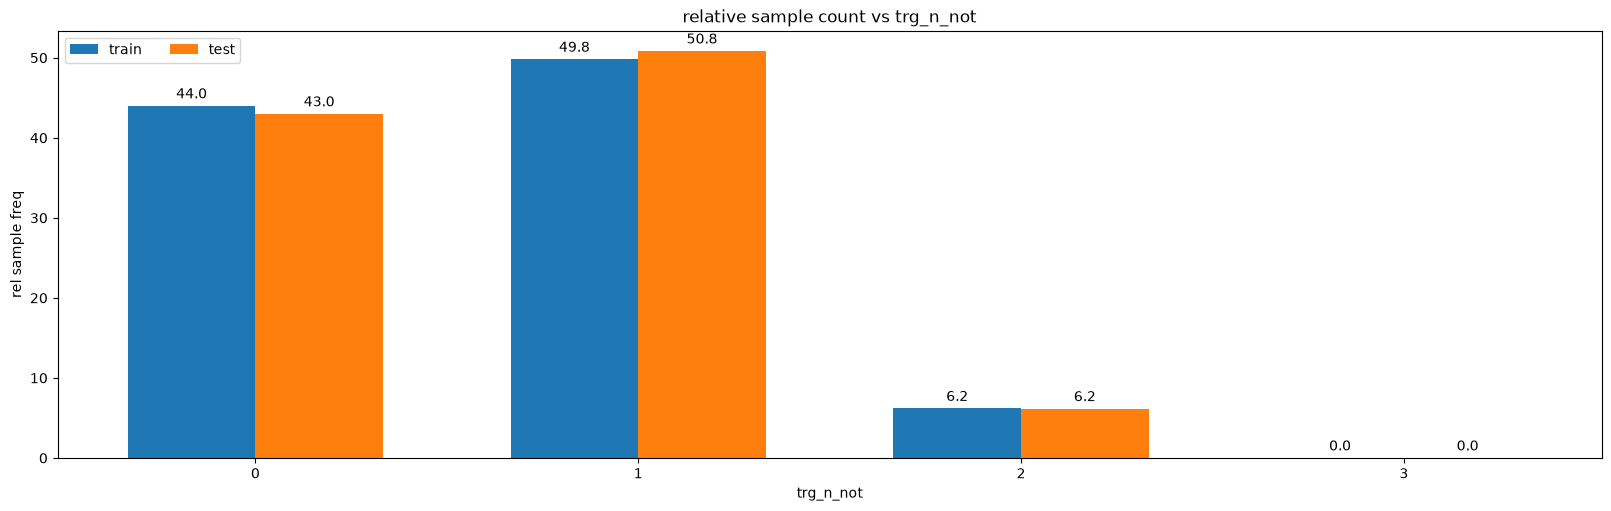

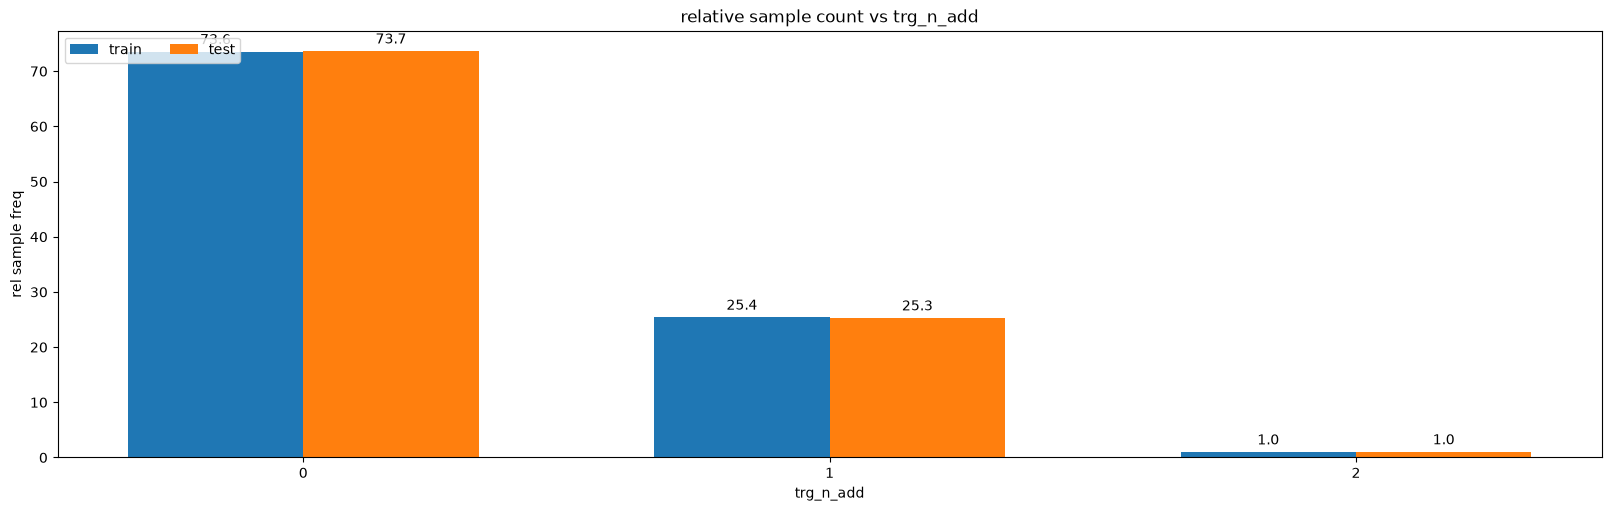

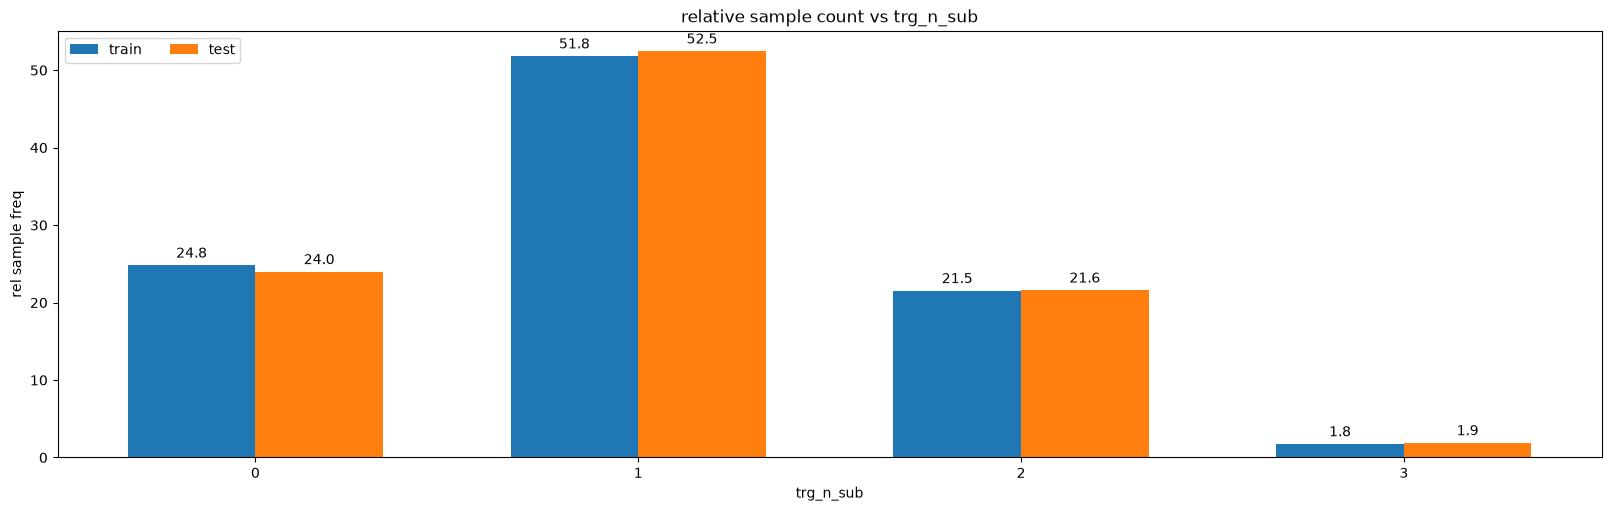

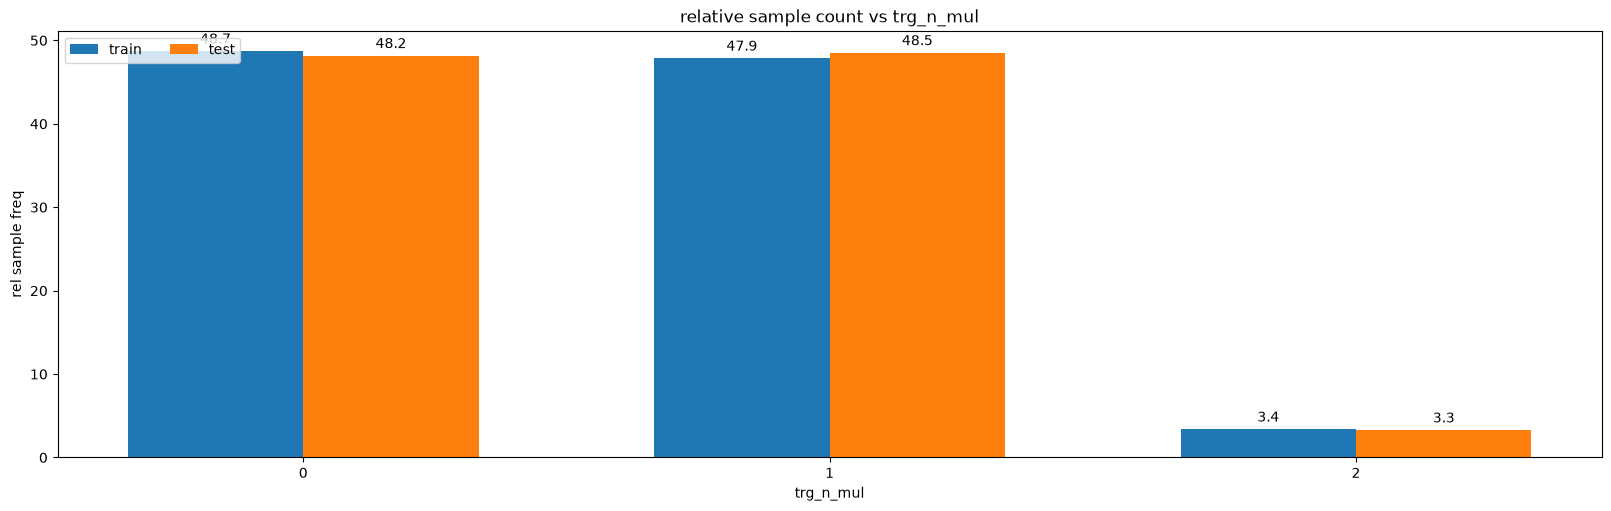

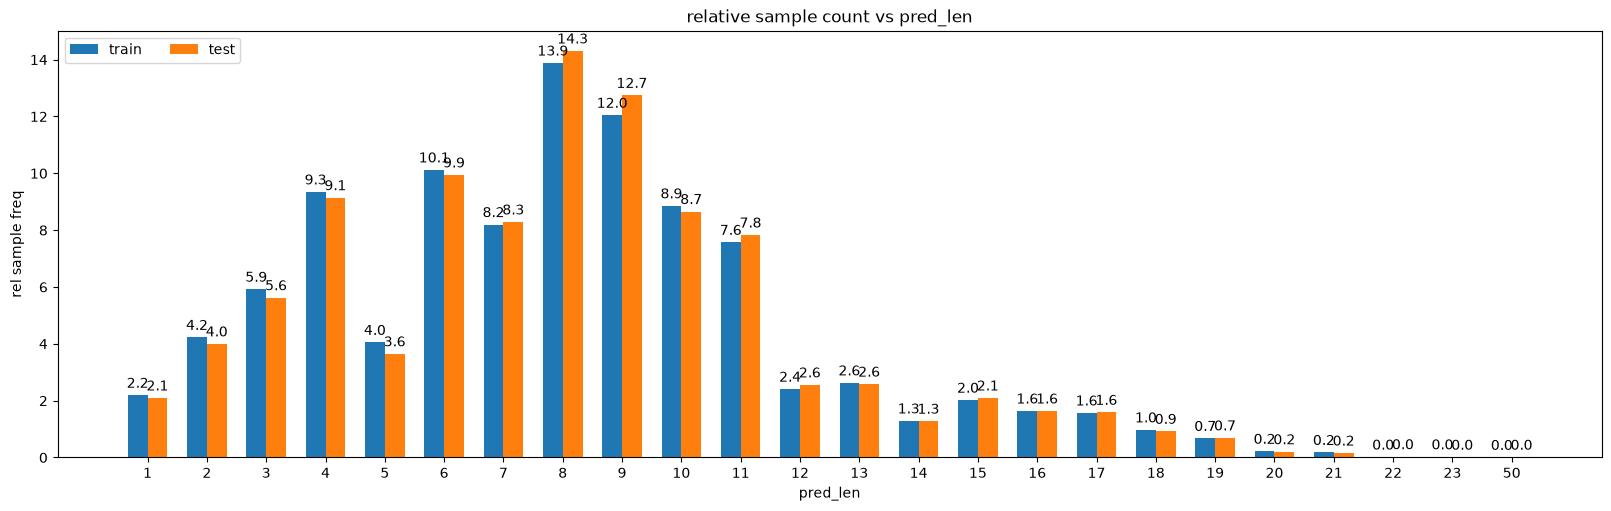

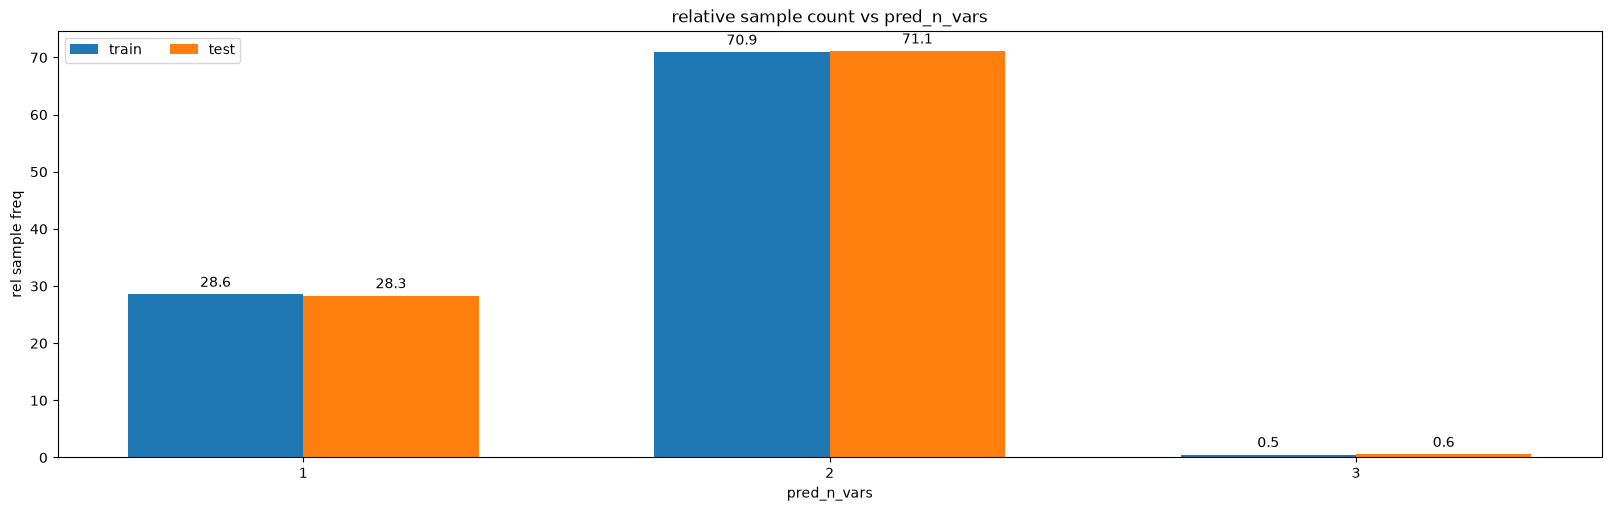

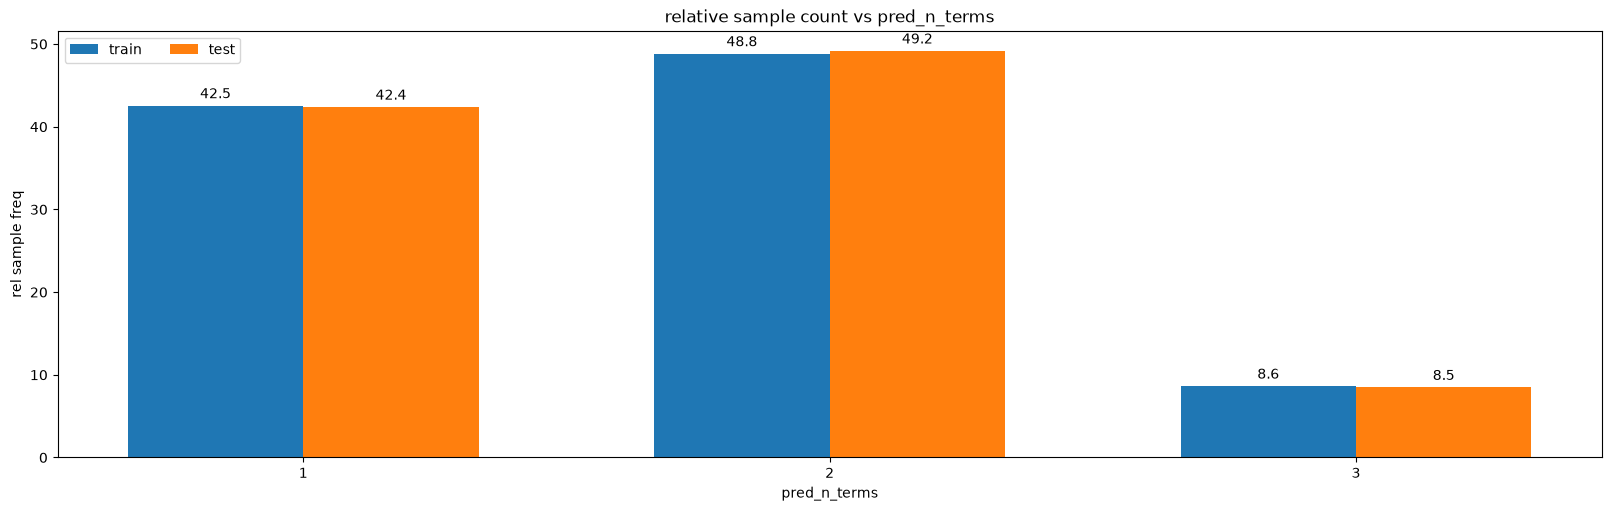

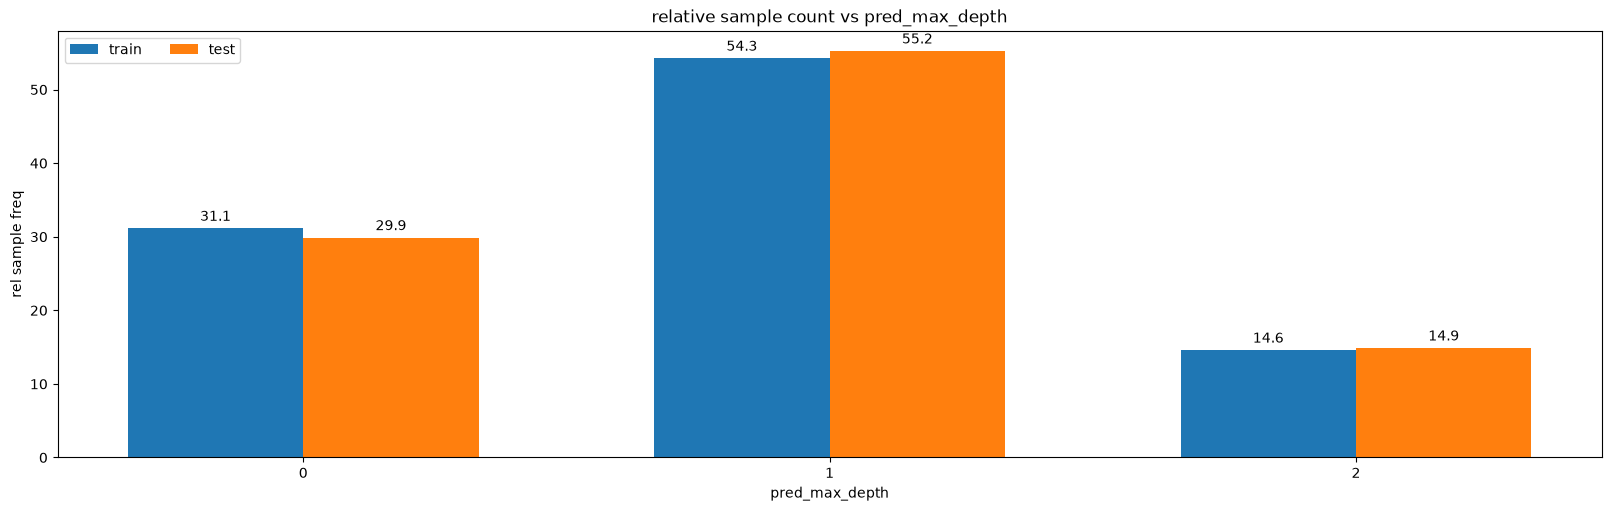

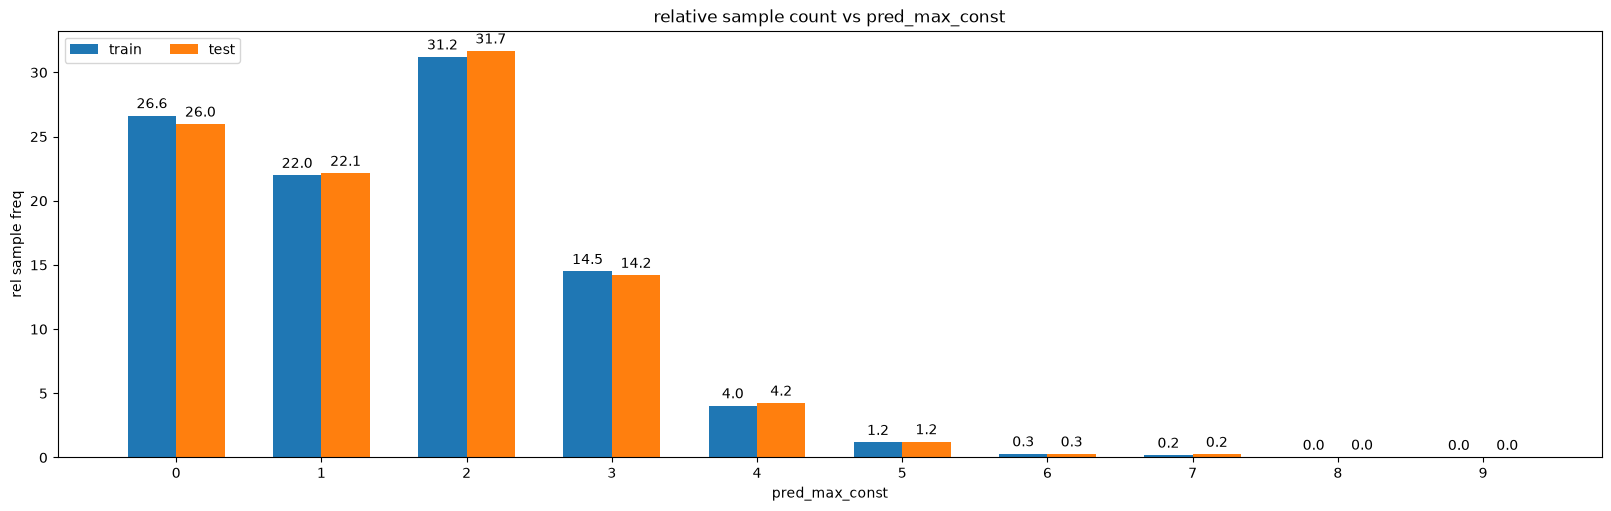

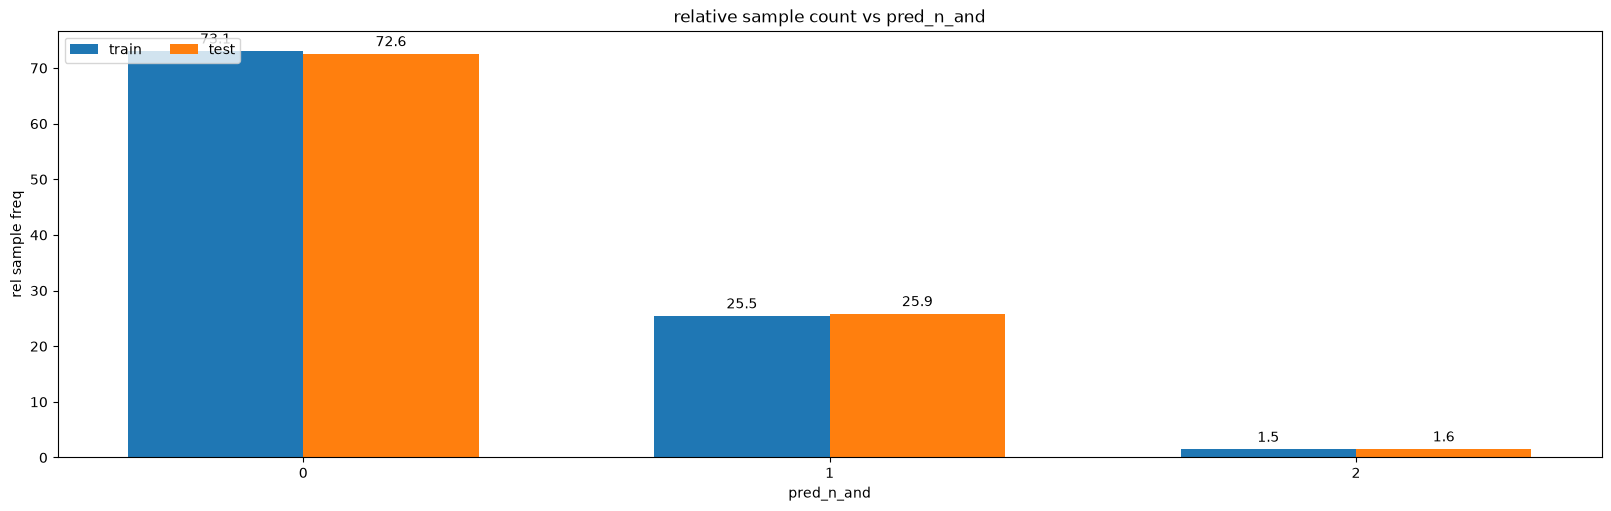

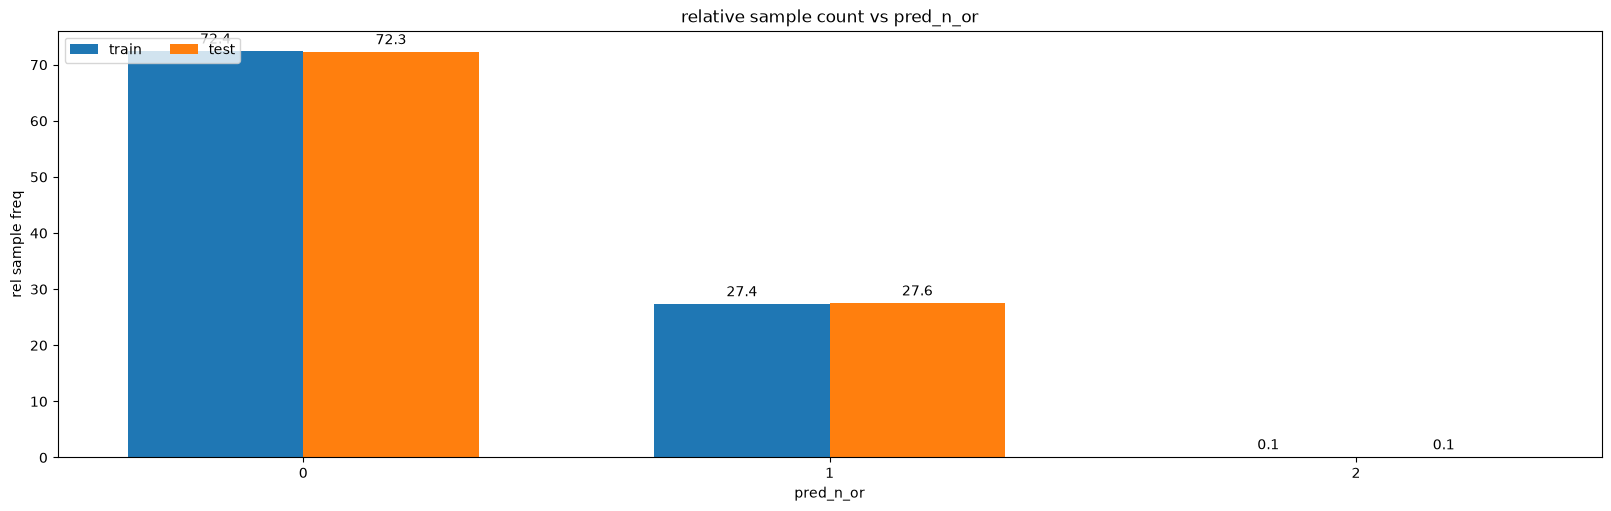

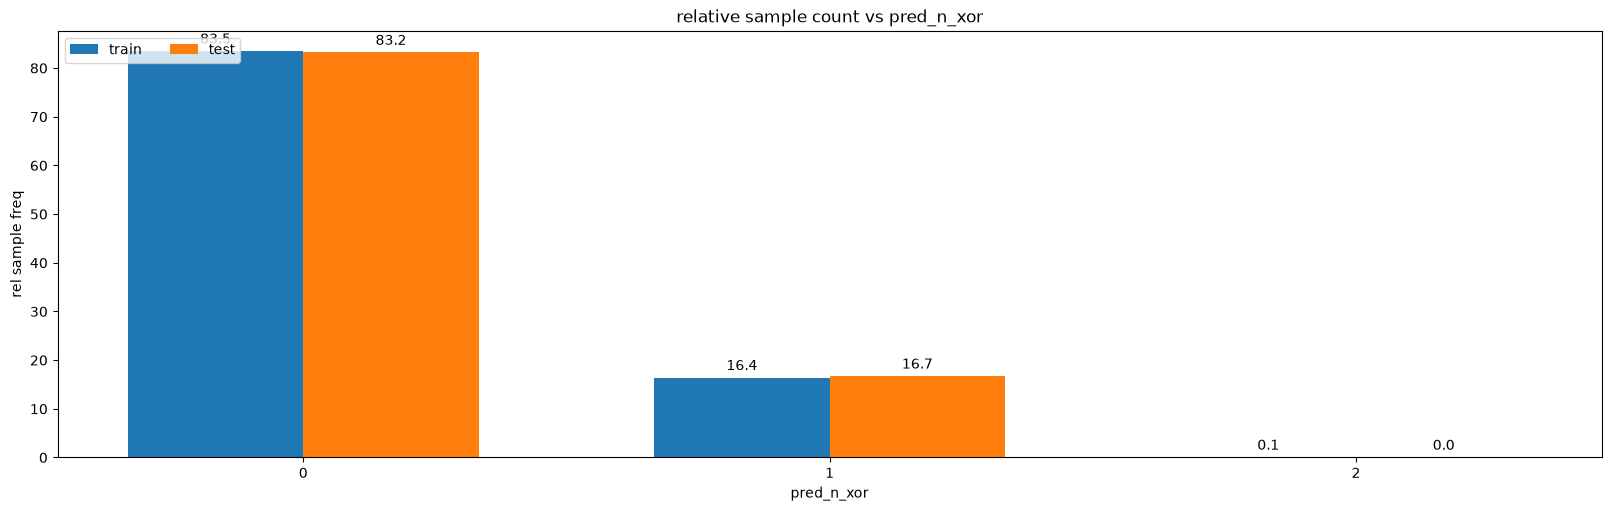

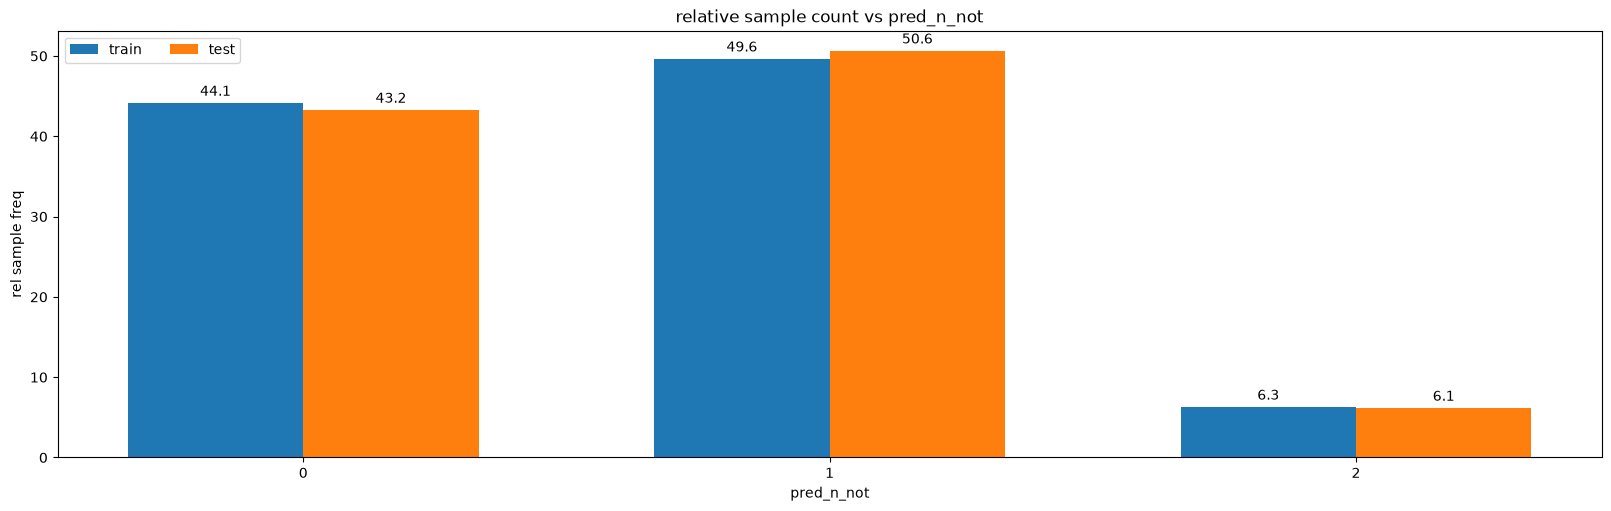

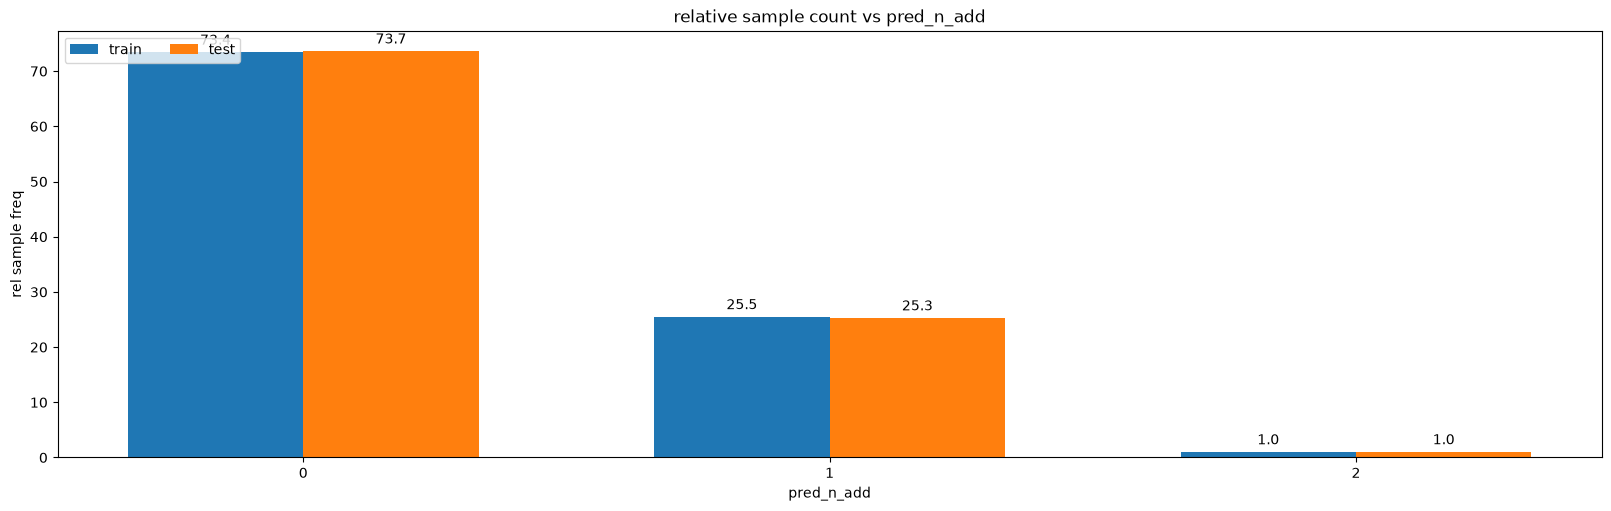

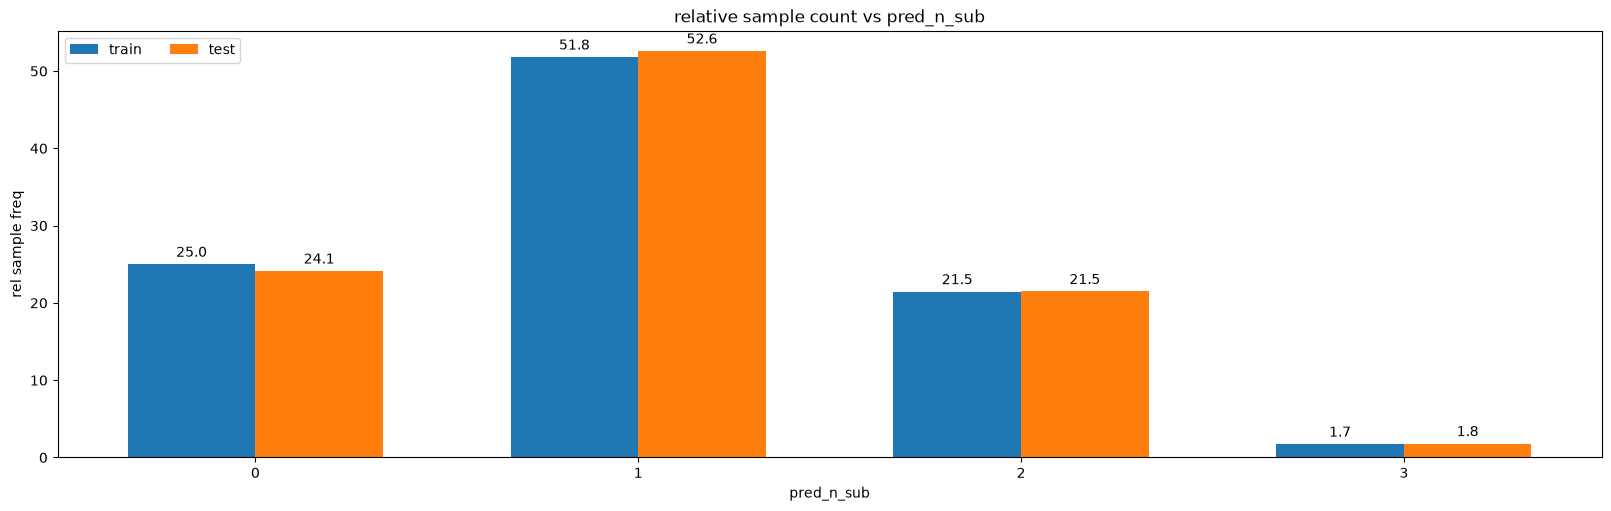

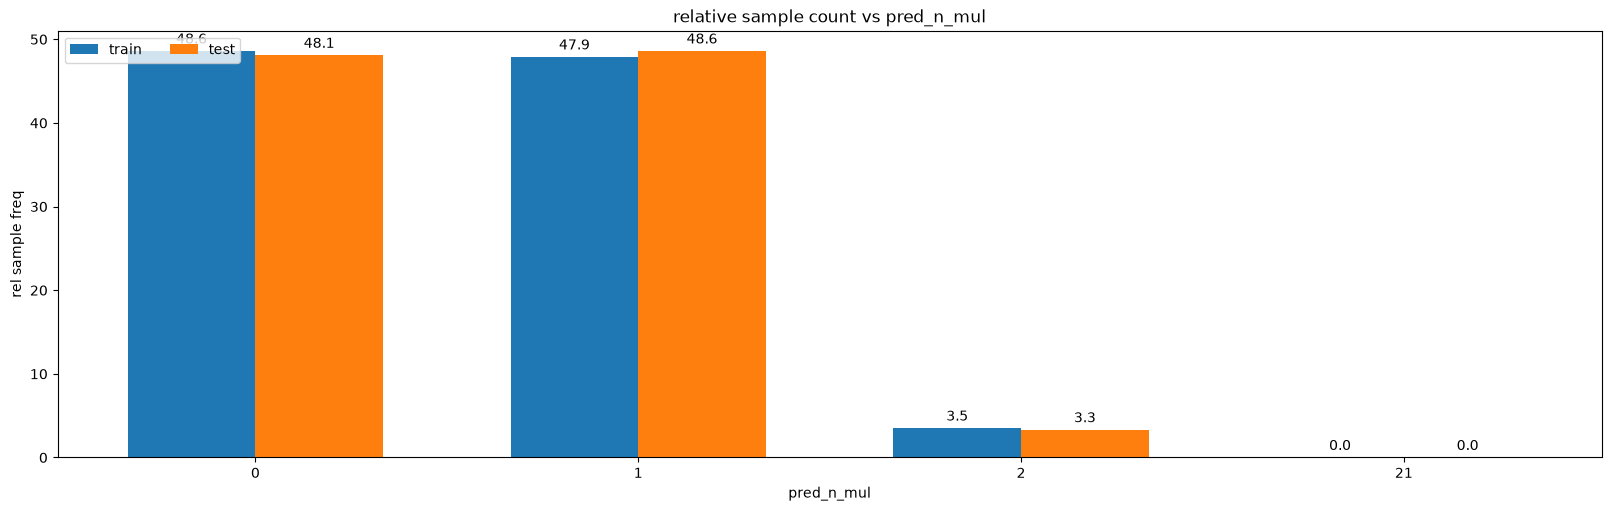

In [6]:
for label_name in labels_:
    plot_relative_sample_frequencies(label_name, df_train, df_test)

## 2. JS divergences between train and test sample distributions for different labels.

JS is better for our task because it's symmetric, i.e JS(a||b) = JS(b||a), while KL is not symmetric.

JS is defined as follows:

JS = (KL(a||b) + KL(b||a)) / 2

0 <= JS(a||b) <= ln2 = 0.6931

We use the function **jensenshannon** from scipy, it returns the square root of js, so we square it.

In [7]:
def compute_JS_divs(label_names):
    JS_divs = {}

    for label_name in label_names:
        df_train_terms_count = df_train.groupby(label_name)["correct"].count()
        df_test_terms_count = df_test.groupby(label_name)["correct"].count()
        
        joint_df = pd.concat([df_train_terms_count, df_test_terms_count], axis=1).fillna(0)
        
        indices, train_counts, test_counts = joint_df.index, joint_df.iloc[:, 0].to_numpy(), joint_df.iloc[:, 1].to_numpy().astype(np.int64)
        
        n_samples_train = df_train.shape[0]
        n_samples_test = df_test.shape[0]
        
        train_rel_counts = (train_counts / n_samples_train) * 100
        test_rel_counts = (test_counts / n_samples_test) * 100

        js_div = jensenshannon(train_rel_counts, test_rel_counts) ** 2
        JS_divs[label_name] = [js_div]
    return JS_divs

In [8]:
JS_divs = compute_JS_divs(labels_)

In [9]:
df_js = pd.DataFrame.from_dict(JS_divs).T
df_js.sort_values(by=[0], ascending=False)

,0
src_len,0.001008
trg_len,0.000381
src_max_const,0.000316
pred_len,0.000249
src_n_sub,0.000216
src_n_terms,0.000165
src_n_or,0.000155
src_n_not,0.000149
trg_max_const,0.000142
pred_max_depth,0.000096


Comment: sorted by decreasing dissimilarity. All distributions are very similar.